# Démo 7 · Un micro VLM : poser une question à une photo

Un **modèle vision-langage** (*Vision Language Model*, VLM) reçoit une image et du texte, et répond par du texte. C’est ce qui permet à ChatGPT, à Claude ou à Gemini de décrire une photo. Dans ce notebook, nous en construisons un tout petit, pièce par pièce, à partir du GPT de la démo 5.

**Ce que nous aurons à la fin :** un modèle écrit dans ce notebook, qui regarde une photo, lit une question sur cette photo et écrit la réponse, un caractère à la fois.

## Le parcours

1. **Les données** (section 1). Des photos réduites à 64 × 64 pixels, chacune avec une question et sa réponse. Le texte est découpé en caractères, comme dans la démo 5.
2. **Un modèle qui lit des images** (section 2). Nous reprenons le Transformer de la démo 5 et nous changeons trois choses pour en faire un *Vision Transformer* (ViT) : plus de masque, des morceaux d’image (*patches*) à la place des caractères, et un token de classe pour lire le résultat.
3. **Un modèle qui lit des images et du texte** (sections 3 et 4). Nous plaçons les caractères de la question dans la même séquence que les patches, nous masquons seulement la partie texte, et nous entraînons le modèle à prédire le prochain caractère.
4. **L’utiliser** (section 6). Nous posons des questions sur des photos que le modèle n’a jamais vues. La section 5 dit ce que les vrais VLM font autrement.

Le code vient du dépôt [`micro_vlm`](https://github.com/milarobotlearningcourse/micro_vlm) du cours, lui-même adapté du [nanoGPT](https://github.com/karpathy/nanoGPT) d’Andrej Karpathy. Il garde ses noms et ses commentaires en anglais.

## Plan

1. Préparer les données
    1. Ramener les images à une seule taille
    2. Préparer le texte et le découper en tokens
1. Créer un ViT à partir du code du GPT
    1. Passer à un encodeur
    2. Découper l’image en patches
1. Un modèle multimodal : le VLM
    1. Remettre le texte en entrée
    2. Rendre le masque causal pour les tokens de texte
    3. Compléter le texte (*padding*) pour allonger le contexte et apprendre plus vite
    4. Former les batchs à partir de sous-chaînes
1. Entraîner le modèle
    1. Nombre de couches et optimisation
    2. Initialisation
1. Encoder le texte avec T5
1. Générer une sortie avec le modèle

## Configuration : Colab ou en local

**Google Colab (le plus simple) :** [ouvrez le notebook dans Colab](https://colab.research.google.com/github/milarobotlearningcourse/data_science/blob/main/demo_7/notebooks/fr/01_micro_vlm.ipynb) et choisissez un GPU (**Exécution → Modifier le type d’exécution**). La cellule ci-dessous installe les deux petits paquets qui manquent.

**En local :** lancez `uv sync --group vlm` à la racine du dépôt `ift3700-6758`, puis sélectionnez le noyau `.venv`. Le notebook choisit tout seul un GPU NVIDIA (`cuda`), sinon le GPU d’un Mac récent (`mps`), sinon le CPU.

Les données (266 Mo) sont téléchargées une fois depuis Hugging Face.

In [1]:
## Run this cell first. It installs what is missing, finds the config file and picks the device.
import importlib.util, os, subprocess, sys, urllib.request
from pathlib import Path

missing = [package for package, module in [("python-box", "box"), ("einops", "einops"), ("datasets", "datasets")]
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import torch

## The config file of the original repo: next to this notebook in the course repo, downloaded otherwise (Colab)
CONFIG_URL = "https://raw.githubusercontent.com/milarobotlearningcourse/micro_vlm/f3bcb295b0bd24c81af1b2e1775a553b329754dd/conf/micro-vlm-64pix.yaml"
local_configs = [folder / "demo_7" / "conf" / "micro-vlm-64pix.yaml" for folder in [Path.cwd(), *Path.cwd().parents]]
config_path = next((str(path) for path in local_configs if path.exists()), os.path.join("conf", "micro-vlm-64pix.yaml"))
if not os.path.exists(config_path):
    os.makedirs("conf", exist_ok=True)
    urllib.request.urlretrieve(CONFIG_URL, config_path)

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Config:", os.path.relpath(config_path), "| device:", device, "| PyTorch", torch.__version__)

Config: ../../demo_7/conf/micro-vlm-64pix.yaml | device: mps | PyTorch 2.14.0


In [2]:
# @title Fonctions de dessin (aucune notion nouvelle ici : exécutez la cellule et passez à la suite)
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import display as ipy_display
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle

C_IMG, C_TXT, C_CLS = "#eb6834", "#2a78d6", "#2e9e5b"
INK, MUTED, FAINT = "#0b0b0b", "#6b6b6b", "#e4e4e4"
OK_MARK, BAD_MARK = "✓", "✗"


def _to_numpy(image):
    if torch.is_tensor(image):
        image = image.detach().cpu().numpy()
    return np.asarray(image, dtype=np.uint8)


def _photo(ax, image, title=None, caption=None, interpolation="nearest"):
    ax.imshow(_to_numpy(image), interpolation=interpolation)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    lines = ([textwrap.fill(title, 32)] if title is not None else []) + ([caption] if caption is not None else [])
    if lines:
        ax.set_title("\n".join(lines), fontsize=9, loc="left", color=INK)


def _strip(ax, x, y, colors, width=1.0, height=1.0, alpha=1.0, texts=None, fontsize=8, text_colors=None):
    for i, color in enumerate(colors):
        ax.add_patch(Rectangle((x + i * width, y), width * 0.9, height, facecolor=color, edgecolor="none", alpha=alpha))
        if texts is not None and texts[i] != "":
            text_color = "white" if text_colors is None else text_colors[i]
            ax.text(x + i * width + width * 0.45, y + height / 2, texts[i], ha="center", va="center",
                    fontsize=fontsize, color=text_color, family="monospace", alpha=alpha)


def show_flow(stage=None):
    alpha = lambda s: 1.0 if stage in (None, s) else 0.2
    fig, ax = plt.subplots(figsize=(12.5, 3.9))
    ax.set_xlim(0, 125)
    ax.set_ylim(-2, 39)
    ax.axis("off")

    def label(x, y, text, s, fontsize=9, color=INK, ha="center", weight="normal"):
        ax.text(x, y, text, alpha=alpha(s), fontsize=fontsize, color=color, ha=ha, va="center", fontweight=weight)

    def arrow(x0, y0, x1, y1, s, rad=0.0):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops={"arrowstyle": "->", "lw": 1.4, "color": MUTED, "alpha": alpha(s), "connectionstyle": f"arc3,rad={rad}"})

    def card(x, y, w, h, text, s):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.2,rounding_size=0.8", facecolor="white",
                                    edgecolor=MUTED, linewidth=1.2, alpha=alpha(s)))
        label(x + w / 2, y + h / 2, text, s)

    label(1, 36.5, "1 · Les données", 1, ha="left", weight="bold")
    card(1, 22, 14, 8, "une photo\n64 × 64", 1)
    card(1, 6, 14, 8, "une question\n(du texte)", 1)

    label(22, 36.5, "2 · Lire une image (ViT)", 2, ha="left", weight="bold")
    arrow(16, 26, 22, 26, 2)
    _strip(ax, 23, 24.4, [C_IMG] * 8, width=2.2, height=3.2, alpha=alpha(2))
    label(31.8, 21.5, "64 patches = 64 tokens", 2, fontsize=8, color=MUTED)

    label(50, 36.5, "3 et 4 · Image et texte dans une même séquence (VLM)", 3, ha="left", weight="bold")
    arrow(16, 10, 22, 10, 3)
    _strip(ax, 23, 8.4, [C_TXT] * 8, width=2.2, height=3.2, alpha=alpha(3))
    label(31.8, 5.5, "32 caractères = 32 tokens", 3, fontsize=8, color=MUTED)
    arrow(42, 25, 49, 20, 3)
    arrow(42, 11, 49, 16, 3)
    _strip(ax, 50, 16.4, [C_IMG] * 5 + [C_TXT] * 4 + [C_CLS], width=2.2, height=3.2, alpha=alpha(3))
    label(61, 13.5, "patches · caractères · token de classe", 3, fontsize=8, color=MUTED)
    arrow(73, 18, 78, 18, 3)
    card(79, 13.5, 15, 9, "4 blocs\nTransformer", 3)
    arrow(95, 18, 100, 18, 3)
    card(101, 13.5, 17, 9, "le prochain\ncaractère", 3)

    arrow(109.5, 13, 42, 8.5, 4, rad=-0.2)
    label(76, -0.5, "6 · Répondre : on ajoute ce caractère au texte, et on recommence", 4, weight="bold")

    ax.set_title("Le parcours du notebook : d’une photo et d’une question à une réponse", loc="left", fontsize=11)
    plt.show()


def show_full_size(dataset, row=0):
    small = _to_numpy(dataset[int(row)]["image"])
    try:
        import datasets as hf_datasets
        stream = hf_datasets.load_dataset("merve/vqav2-small", split="validation", streaming=True)
        full = np.asarray(next(iter(stream.skip(int(row))))["image"].convert("RGB"))
    except Exception as error:
        full = None
        print("Photo d’origine non téléchargée (", type(error).__name__, ") : seule la version 64 × 64 est affichée.")
    panels = [(small, "Ce que le modèle reçoit : 64 × 64 pixels")]
    if full is not None:
        panels.insert(0, (full, f"La photo d’origine : {full.shape[1]} × {full.shape[0]} pixels"))
    fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4), squeeze=False)
    for ax, (image, title) in zip(axes[0], panels):
        ax.imshow(image, interpolation="nearest")
        ax.set_title(title, fontsize=10, loc="left")
        ax.axis("off")
    fig.suptitle(f"« {dataset[int(row)]['question']} » À 64 × 64, tout tient sur un petit GPU, mais les détails disparaissent",
                 x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def show_tokens(text, encode):
    ids = encode(text)
    fig, ax = plt.subplots(figsize=(min(12.5, 0.34 * len(ids) + 0.4), 1.5))
    ax.set_xlim(0, len(ids))
    ax.set_ylim(-0.9, 1.05)
    ax.axis("off")
    _strip(ax, 0, 0, [C_TXT] * len(ids), texts=["·" if ch == " " else ch for ch in text], fontsize=10)
    for i, token in enumerate(ids):
        ax.text(i + 0.45, -0.45, str(token), ha="center", va="center", fontsize=8, color=MUTED)
    ax.set_title("Un caractère = un token : chaque caractère devient un entier (en dessous)", loc="left", fontsize=10)
    plt.show()


def show_text_stats(dataset, cfg):
    questions, answers = list(dataset["question"]), list(dataset["multiple_choice_answer"])
    lengths = np.array([len(q) for q in questions])
    counts = {}
    for answer in answers:
        counts[answer] = counts.get(answer, 0) + 1
    top = sorted(counts.items(), key=lambda item: -item[1])[:12]

    fig, (ax_len, ax_top) = plt.subplots(1, 2, figsize=(12, 3.6))
    ax_len.hist(lengths, bins=np.arange(0, lengths.max() + 2), color=C_TXT, rwidth=0.85)
    ax_len.axvline(cfg.max_block_size, color=INK, lw=1, ls="--")
    ax_len.text(cfg.max_block_size + 1, ax_len.get_ylim()[1] * 0.92, f"contexte du modèle : {cfg.max_block_size} caractères", fontsize=9, color=INK)
    ax_len.set_xlabel("Longueur de la question (caractères)")
    ax_len.set_ylabel("Nombre de questions")
    ax_len.set_title(f"Les questions sont courtes : {lengths.mean():.0f} caractères en moyenne", fontsize=10, loc="left")

    names = [name for name, _ in top]
    shares = [100 * count / len(answers) for _, count in top]
    bars = ax_top.barh(names, shares, height=0.6, color=C_TXT)
    ax_top.bar_label(bars, labels=[f"{share:.1f} %".replace(".", ",") for share in shares], padding=3, fontsize=8, color=INK)
    ax_top.invert_yaxis()
    ax_top.set_xlim(0, max(shares) * 1.18)
    ax_top.set_xticks(range(0, int(max(shares)) + 1, 5))
    ax_top.set_xlabel("Part des réponses (%)")
    ax_top.set_title(f"Les réponses aussi : « yes » et « no » en couvrent {shares[0] + shares[1]:.0f} % ({len(counts):,} réponses différentes)".replace(",", " "),
                     fontsize=10, loc="left")
    for ax in (ax_len, ax_top):
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def show_attention(wei_masked, wei):
    fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.5))
    panels = [(wei_masked, "Avec le masque (GPT) : le futur est caché"), (wei, "Votre `wei` : dans un encodeur, chaque token voit tout")]
    for ax, (matrix, title) in zip(axes, panels):
        ax.imshow(matrix.detach().cpu(), cmap="Blues", vmin=0, vmax=1)
        ax.set_title(title, fontsize=9, loc="left")
        ax.set_xlabel("Token consulté")
        ax.set_ylabel("Token qui consulte")
    fig.suptitle("Les poids d’attention d’une tête (non entraînée)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def show_gpt_vit_vlm():
    models = [
        ("GPT (démo 5)", [C_TXT] * 8, list("Bonjour "), np.tril(np.ones((8, 8))), "entrée : des caractères\nsortie : le prochain caractère, à chaque position"),
        ("ViT (section 2)", [C_CLS] + [C_IMG] * 8, ["C"] + [""] * 8, np.ones((9, 9)), "entrée : des patches + un token de classe (C)\nsortie : une classe, lue sur le token de classe"),
        ("VLM (section 3)", [C_IMG] * 6 + [C_TXT] * 4 + [C_CLS], [""] * 6 + list("Quel") + ["C"], None, "entrée : des patches, des caractères, C\nsortie : le prochain caractère, lu sur C"),
    ]
    vlm_mask = np.tril(np.ones((11, 11)))
    vlm_mask[:6] = 1
    fig, axes = plt.subplots(2, 3, figsize=(12, 4.6), gridspec_kw={"height_ratios": [1, 2.6]})
    for column, (title, colors, texts, mask, caption) in enumerate(models):
        ax = axes[0, column]
        ax.set_xlim(0, 11)
        ax.set_ylim(-0.2, 1.2)
        ax.axis("off")
        _strip(ax, 0, 0, colors, texts=texts, fontsize=9)
        ax.set_title(title, fontsize=11, loc="left", fontweight="bold")
        ax = axes[1, column]
        mask = vlm_mask if mask is None else mask
        ax.imshow(mask, cmap=ListedColormap([FAINT, "#5c5c5c"]), vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_ylabel("token qui consulte", fontsize=8, color=MUTED)
        ax.set_xlabel("token consulté (foncé = permis)\n\n" + caption, fontsize=8.5, color=INK)
    fig.suptitle("Le même Transformer, trois fois : ce qui change, c’est la séquence en entrée, le masque et ce qu’on lit en sortie",
                 x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def show_patches(image, patches, cfg):
    image, p = _to_numpy(image), cfg.patch_size
    side = image.shape[0] // p
    tiles = _to_numpy(patches).reshape(-1, p, p, 3)
    columns, gap = 16, 2
    rows = int(np.ceil(len(tiles) / columns))
    canvas = np.full((rows * (p + gap) - gap, columns * (p + gap) - gap, 3), 255, dtype=np.uint8)
    for k, tile in enumerate(tiles):
        r, c = divmod(k, columns)
        canvas[r * (p + gap):r * (p + gap) + p, c * (p + gap):c * (p + gap) + p] = tile

    fig, (ax_image, ax_tiles) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2.6]})
    ax_image.imshow(image, interpolation="nearest")
    for k in range(1, side):
        ax_image.axhline(k * p - 0.5, color="white", lw=0.8)
        ax_image.axvline(k * p - 0.5, color="white", lw=0.8)
    ax_image.set_title(f"La photo, découpée en {side} × {side} patches", fontsize=10, loc="left")
    ax_tiles.imshow(canvas, interpolation="nearest")
    ax_tiles.set_title(f"La séquence que reçoit le Transformer : {len(tiles)} tokens de {p} × {p} × 3 = {p * p * 3} nombres,\n"
                       "lus de gauche à droite puis de haut en bas", fontsize=10, loc="left")
    for ax in (ax_image, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def show_positions(positions):
    fig, ax = plt.subplots(figsize=(12, 3.4))
    image = ax.imshow(positions.detach().cpu(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_xlabel("Dimension du vecteur")
    ax.set_ylabel("Position du token dans la séquence")
    ax.set_title("Une ligne par position : chaque token reçoit une signature différente, ajoutée à son vecteur.\n"
                 "Sans elle, le Transformer ne saurait pas où se trouve un patch dans la photo", fontsize=10, loc="left")
    fig.colorbar(image, ax=ax, pad=0.01)
    plt.tight_layout()
    plt.show()


def show_sequence(kind, cfg):
    n_patches = (cfg.image_shape[0] // cfg.patch_size) ** 2
    if kind == "vit":
        parts = [("token de classe", 1, C_CLS), (f"{n_patches} patches de la photo", n_patches, C_IMG)]
        title = "La séquence du ViT : le token de classe d’abord, puis les patches. La classe se lit sur le premier token"
    else:
        parts = [(f"{n_patches} patches de la photo", n_patches, C_IMG), (f"{cfg.max_block_size} caractères", cfg.max_block_size, C_TXT), ("token de classe", 1, C_CLS)]
        title = "La séquence du VLM : la photo, puis le texte, puis le token de classe. Le prochain caractère se lit sur le dernier token"
    total = sum(count for _, count, _ in parts)
    fig, ax = plt.subplots(figsize=(12.5, 1.7))
    ax.set_xlim(-1, total + 1)
    ax.set_ylim(-1.6, 2.3)
    ax.axis("off")
    start = 0
    for name, count, color in parts:
        _strip(ax, start, 0, [color] * count)
        anchor = start + count / 2 if count > 1 else start + (3 if start == 0 else -2)
        ax.text(anchor, 1.6, name, ha="center", va="center", fontsize=9, color=INK)
        ax.text(start + 0.45, -0.7, str(start), ha="center", va="center", fontsize=8, color=MUTED)
        start += count
    if parts[-1][1] > 1:
        ax.text(total - 0.55, -0.7, str(total - 1), ha="center", va="center", fontsize=8, color=MUTED)
    ax.set_title(title, loc="left", fontsize=10)
    plt.show()


@torch.no_grad()
def _greedy_answer(model, image, question, max_new_tokens=12):
    was_training = model.training
    model.eval()
    context = torch.tensor([encode_txt(question.rjust(cfg.max_block_size)[-cfg.max_block_size:])], device=cfg.device)
    for _ in range(max_new_tokens):
        logits, _ = model(context[:, -cfg.max_block_size:], image[None].float() / 255.0, None)
        context = torch.cat((context, logits.argmax(-1, keepdim=True)), dim=1)
        if decode_txt(context[0, -1:].tolist()) == " ":
            break
    model.train(was_training)
    return decode_txt(context[0, cfg.max_block_size:].tolist()).strip()


class LiveFigure:
    def __init__(self, title, chance=None, chance_label="", example=None):
        self.title, self.chance, self.chance_label, self.example = title, chance, chance_label, example
        self.steps, self.train, self.val, self.handle = [], [], [], None

    def update(self, step, losses, model=None):
        self.steps.append(step)
        self.train.append(float(losses["train"]))
        self.val.append(float(losses["val"]))
        with_example = self.example is not None and model is not None
        fig, axes = plt.subplots(1, 2 if with_example else 1, figsize=(11.5 if with_example else 7.5, 3.5), squeeze=False,
                                 gridspec_kw={"width_ratios": [2.4, 1]} if with_example else None)
        ax = axes[0, 0]
        ax.plot(self.steps, self.train, color=C_TXT, lw=2, marker="o", ms=4, label="Entraînement")
        ax.plot(self.steps, self.val, color=C_IMG, lw=2, marker="o", ms=4, label="Validation (lignes mises de côté)")
        if self.chance is not None:
            ax.axhline(self.chance, color=MUTED, lw=1, ls="--")
            ax.text(0.99, self.chance, self.chance_label + " ", transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontsize=8, color=MUTED)
        ax.set_xlabel("Pas d’entraînement")
        ax.set_ylabel("Perte d’entropie croisée")
        ax.set_title(f"{self.title} · pas {step}", fontsize=11, loc="left")
        ax.legend(frameon=False, fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
        if with_example:
            image, question, truth = self.example
            ax = axes[0, 1]
            _photo(ax, image, question, f"modèle : {_greedy_answer(model, image, question) or '(rien)'}  ·  attendu : {truth}")
        plt.tight_layout()
        if self.handle is None:
            self.handle = ipy_display.display(fig, display_id=True)
        else:
            self.handle.update(fig)
        plt.close(fig)


@torch.no_grad()
def show_vit_predictions(model, dataset, cfg, count=8):
    model.eval()
    n_train = int(0.9 * len(dataset["image"]))
    images = dataset["image"][n_train:]
    half = images.shape[1] // 2
    truth = (images[:, half:].float().mean(dim=(1, 2, 3)) > images[:, :half].float().mean(dim=(1, 2, 3))).long()
    predicted = torch.cat([model(images[i:i + 256].float() / 255.0)[0].argmax(-1) for i in range(0, len(images), 256)])
    accuracy = (predicted == truth).float().mean().item()
    majority = max(truth.float().mean().item(), 1 - truth.float().mean().item())
    names = ["haut", "bas"]
    fig, axes = plt.subplots(1, count, figsize=(12.5, 2.4))
    for i, ax in enumerate(axes):
        ax.imshow(_to_numpy(images[i]), interpolation="nearest")
        ax.axhline(half - 0.5, color="white", lw=1)
        ax.axis("off")
        right = bool(predicted[i] == truth[i])
        guess = names[int(predicted[i])] if int(predicted[i]) < 2 else "?"
        ax.set_title(f"{OK_MARK if right else BAD_MARK} prédit : {guess}\nvrai : {names[int(truth[i])]}", fontsize=9, loc="left")
    fig.suptitle(f"Quelle moitié est la plus claire ? Sur {len(images)} photos jamais vues à l’entraînement, le ViT a raison "
                 f"{100 * accuracy:.0f} % du temps (toujours répondre « {names[int(truth.float().mean() > 0.5)]} » : {100 * majority:.0f} %)",
                 x=0.01, ha="left", fontsize=10)
    plt.tight_layout()
    plt.show()
    model.train()


def show_block_mask(cfg):
    n_patches, n_text = (cfg.image_shape[0] // cfg.patch_size) ** 2, cfg.max_block_size
    total = n_patches + n_text + 1
    mask = np.tril(np.ones((total, total)))
    mask[:n_patches] = 1
    fig, ax = plt.subplots(figsize=(6.6, 6))
    ax.imshow(mask, cmap=ListedColormap([FAINT, "#5c5c5c"]), vmin=0, vmax=1, interpolation="nearest")
    for edge in (n_patches - 0.5, n_patches + n_text - 0.5):
        ax.axhline(edge, color="white", lw=1.5)
        ax.axvline(edge, color="white", lw=1.5)
    ax.text(n_patches / 2, n_patches / 2, "Les patches consultent toute la séquence :\nla photo n’a ni passé ni futur",
            ha="center", va="center", fontsize=9, color="white")
    ax.text(n_patches / 2, n_patches + n_text / 2, "Chaque caractère consulte\ntoute la photo…", ha="center", va="center", fontsize=9, color="white")
    ax.text(n_patches + n_text * 0.72, n_patches + n_text * 0.3, "…mais pas\nles caractères\nsuivants", ha="center", va="center", fontsize=8, color=INK)
    ax.set_xticks([n_patches / 2, n_patches + n_text / 2, total - 1])
    ax.set_xticklabels([f"{n_patches} patches", f"{n_text} caractères", "classe"], fontsize=9)
    ax.set_yticks([n_patches / 2, n_patches + n_text / 2, total - 1])
    ax.set_yticklabels([f"{n_patches} patches", f"{n_text} caractères", "classe"], fontsize=9, rotation=90, va="center")
    for (x, color) in zip(ax.get_xticklabels(), (C_IMG, C_TXT, C_CLS)):
        x.set_bbox({"facecolor": color, "edgecolor": "none", "alpha": 0.18, "pad": 2})
    for (y, color) in zip(ax.get_yticklabels(), (C_IMG, C_TXT, C_CLS)):
        y.set_bbox({"facecolor": color, "edgecolor": "none", "alpha": 0.18, "pad": 2})
    ax.set_xlabel("Token consulté")
    ax.set_ylabel("Token qui consulte")
    ax.set_title("Le masque par blocs (foncé = permis) : causal pour le texte seulement.\n"
                 "Le token de classe, en dernier, consulte tout", fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()


def show_windows(dataset, cfg, row, decode, max_windows=5):
    ids = dataset["text2"][row].tolist()
    text = decode(ids)
    block, length = cfg.max_block_size, int(dataset["text_lengths"][row])
    starts = list(range(0, length - (block + 1)))
    if len(starts) > max_windows:
        starts = [starts[int(k)] for k in np.linspace(0, len(starts) - 1, max_windows)]
    chars = ["" if ch == " " else ch for ch in text]
    fig, ax = plt.subplots(figsize=(12.5, 0.5 * (len(starts) + 1) + 1.2))
    ax.set_xlim(-9, len(ids))
    ax.set_ylim(-1.35 * len(starts) - 0.6, 1.6)
    ax.axis("off")
    _strip(ax, 0, 0, [C_TXT if ch != "" else FAINT for ch in chars], texts=chars, fontsize=8)
    ax.text(-0.6, 0.5, "la ligne", ha="right", va="center", fontsize=9, color=INK)
    for k, start in enumerate(starts):
        y = -1.35 * k - 1.7
        colors, text_colors, texts = [], [], []
        for i, ch in enumerate(chars):
            inside, target = start <= i < start + block, i == start + block
            colors.append(INK if target else C_TXT if inside else "white")
            text_colors.append("white")
            texts.append((ch or "·") if target else ch if inside else "")
        _strip(ax, 0, y, colors, texts=texts, fontsize=8, text_colors=text_colors)
        ax.text(-0.6, y + 0.5, f"fenêtre {start}", ha="right", va="center", fontsize=9, color=MUTED)
    for index in (0, block, len(ids) - 1):
        ax.text(index + 0.45, 1.25, str(index), ha="center", va="center", fontsize=8, color=MUTED)
    ax.set_title(f"Une ligne de texte donne plusieurs exemples : {block} caractères en entrée (bleu), le suivant comme cible (noir, · = espace)",
                 loc="left", fontsize=10)
    plt.show()


def show_answers(images, questions, answers, truths):
    count = len(questions)
    fig, axes = plt.subplots(2, count // 2, figsize=(12, 7.8))
    for ax, image, question, answer, truth in zip(axes.ravel(), images, questions, answers, truths):
        mark = OK_MARK if answer == truth else BAD_MARK
        _photo(ax, image, question, f"{mark} modèle : {answer or '(rien)'}  ·  attendu : {truth}")
    right = sum(answer == truth for answer, truth in zip(answers, truths))
    fig.suptitle(f"Des photos jamais vues à l’entraînement : {right} réponse(s) exacte(s) sur {count}", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(h_pad=1.5)
    plt.show()


@torch.no_grad()
def show_class_attention(model, image, question, cfg):
    model.eval()
    captured = []
    hooks = [head.dropout.register_forward_hook(lambda module, inputs, output: captured.append(inputs[0][0, -1].detach().cpu()))
             for head in model.blocks[-1].sa.heads]
    answer = _greedy_answer(model, image, question, max_new_tokens=1)
    for hook in hooks:
        hook.remove()
    side = cfg.image_shape[0] // cfg.patch_size
    weights = torch.stack(captured).mean(0)
    on_photo = weights[:side * side].reshape(side, side).numpy()
    share = 100 * weights[:side * side].sum().item()
    fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.9))
    _photo(axes[0], image, question)
    _photo(axes[1], image)
    overlay = axes[1].imshow(np.kron(on_photo, np.ones((cfg.patch_size, cfg.patch_size))), cmap="magma", alpha=0.65, interpolation="nearest")
    axes[1].set_title(f"Premier caractère écrit : « {answer or 'espace'} »\n{share:.0f} % de son attention va aux 64 patches", fontsize=9, loc="left")
    fig.colorbar(overlay, ax=axes[1], fraction=0.046, pad=0.03, label="Poids d’attention par patch")
    fig.suptitle("Où regarde le token de classe au moment d’écrire ? (dernier bloc, moyenne des têtes)", x=0.01, ha="left", fontsize=10)
    plt.tight_layout()
    plt.show()

Voici le parcours en une image. Elle reviendra au début des sections 2, 3 et 6, avec l’étape en cours mise en évidence.

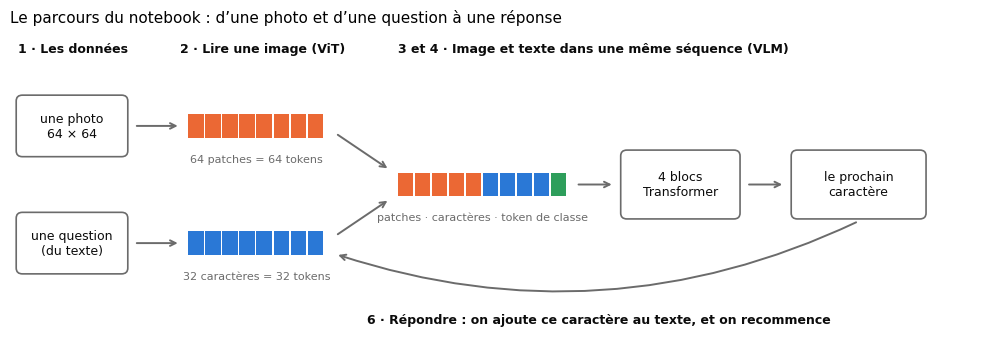

In [3]:
show_flow()

## 1. Préparer les données

La tâche s’appelle *Visual Question Answering* (VQA) : **(photo, question) → réponse**. Nous utilisons un extrait de [VQAv2](https://visualqa.org/), environ 21 000 questions posées par des personnes sur des photos de tous les jours.

Deux choix gardent le modèle assez petit pour s’entraîner en classe :

- **Les photos sont réduites à 64 × 64 pixels.** Une copie déjà réduite du jeu de données est en ligne : c’est elle que nous chargeons.
- **Le texte est découpé en caractères,** avec le tokeniseur de la démo 5.

Question: Is this boy a good pitcher?
multiple_choice_answer: yes


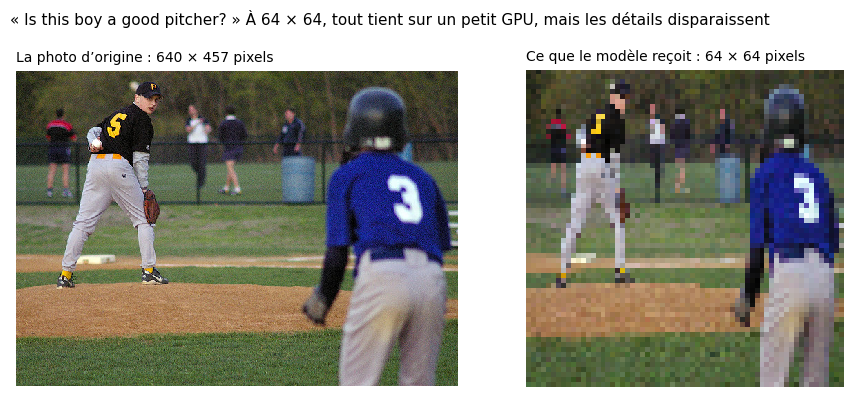

In [4]:
from PIL import Image
from IPython import display
import numpy as np
import cv2

import datasets, cv2
dataset = datasets.load_dataset("gberseth/vqav2-small-64px") ## merve/vqav2-small with the photos already resized to 64x64 (266 MB instead of 3.4 GB)
dataset = dataset['train'] ## this copy has a single split

# extract image & language instruction
ind = 1
image = dataset[ind]["image"]
question = dataset[ind]["question"]
mca = dataset[ind]["multiple_choice_answer"]

# visualize episode
print(f'Question: {question}')
print(f'multiple_choice_answer: {mca}')
### Display the image in the notebook
show_full_size(dataset, row=ind)

### Le texte : des caractères, puis des entiers

La cellule suivante charge la configuration, construit le vocabulaire (tous les caractères qui apparaissent dans les questions et les réponses) et range tout sur le GPU.

Pour chaque photo, la question et la réponse sont collées en **une seule ligne de texte**, complétée par des espaces jusqu’à 65 caractères. Nous verrons à la section 3 pourquoi la question est alignée à droite.

In [6]:
## Let's load the config and prepare the dataset for some training

from box import Box
import os, torch

cfg = Box.from_yaml(filename=config_path) ## config_path comes from the setup cell
cfg.device = device ## cuda or mps if there is one, else cpu (the config file says "cpu")

dataset = datasets.load_dataset(cfg.dataset.to_dataset_name_new) ## the 64x64 copy

# cbuffer = CircularBuffer(cfg.dataset.buffer_size, cfg)
dataset = dataset['train']

chars = sorted(list(set([item for row in dataset["question"] for item in row] + [item for row in dataset["multiple_choice_answer"] for item in row]))) ## Flatten to a long string
cfg.vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode_txt = lambda s: [stoi[c] for c in s] # text encoder to tokens: 
decode_txt = lambda l: ''.join([itos[i] for i in l]) # token decoder to text: 
print("vocab_size:", cfg.vocab_size)
print("example text encode:", encode_txt(dataset["question"][0])) 

# dataset = dataset.add_column("text2", np.array(text))

# dataset.set_format(type="torch", columns=["image", "question", "multiple_choice_answer", "text2"], device=device)

if cfg.dataset.save_initial_dataset:
    dataset__ = {"image": [], "question": [], "multiple_choice_answer": []}
    for i in range(min(cfg.trim, dataset.num_rows)):
        item = dataset[i]
        if item["image"].mode == "RGB":
            dataset__["image"].append(cv2.resize(np.array(item["image"], dtype=np.uint8), (cfg.image_shape[0], cfg.image_shape[1])))
            dataset__["question"].append(item["question"])
            dataset__["multiple_choice_answer"].append(item["multiple_choice_answer"])
    # del dataset
    ## Convert lists to torch tensors
    dataset__["image"] = np.array(dataset__["image"], dtype=np.uint8)
    dataset__["question"] = np.array(dataset__["question"])
    dataset__["multiple_choice_answer"] = np.array(dataset__["multiple_choice_answer"])
    from datasets import Image, Dataset
    dataset = Dataset.from_dict(dataset__)

    new_features = dataset.features.copy()
    new_features["image"] = Image()
    dataset.cast(new_features)
    print('Features:', dataset.features)
    # dataset.save_to_disk("datasets/" + cfg.dataset.to_dataset_name_new + ".hf")
    # dataset.push_to_hub(cfg.dataset.to_dataset_name_new)

images = []
text = []
lengths = []
padding_ = " " * (int(cfg.phrase_length)+1) ## making up 64 for now.
for i in range(min(len(dataset), cfg.trim)):
    text_t = dataset[i]["question"].rjust(cfg.max_block_size)+dataset[i]["multiple_choice_answer"] ## the question is right-aligned in the context, so the answer starts right after it
    lengths.append(min(len(text_t), cfg.phrase_length) + 2) ## plus two: the space that ends the answer can be a target too
    ## Pad the text to at least 64
    text_ = text_t[0:65] + padding_[len(text_t):cfg.phrase_length + 1]
    text.append(np.array(encode_txt(text_[:cfg.phrase_length + 1])))
    assert len(text[-1]) == cfg.phrase_length + 1

    images.append(np.array(dataset[i]["image"], dtype=np.uint8)) ## already 64x64

    assert images[-1].shape == (cfg.image_shape[0], cfg.image_shape[1], cfg.image_shape[2])
dataset_ = {"image": torch.tensor(np.array(images, dtype=np.uint8), dtype=torch.uint8, device=cfg.device),
            "text2": torch.tensor(np.array(text, dtype=np.int32), dtype=torch.long, device=cfg.device),
            "text_lengths": np.array(lengths, dtype=np.int32)
            }

print ('Dataset prepared with {} samples.'.format(len(dataset_["image"])))
{key: value.shape for key, value in dataset_.items()}

vocab_size: 79
example text encode: [48, 60, 57, 70, 57, 0, 53, 70, 57, 0, 72, 60, 57, 0, 63, 61, 56, 71, 0, 70, 61, 56, 61, 66, 59, 25]


Dataset prepared with 21388 samples.


{'image': torch.Size([21388, 64, 64, 3]),
 'text2': torch.Size([21388, 65]),
 'text_lengths': (21388,)}

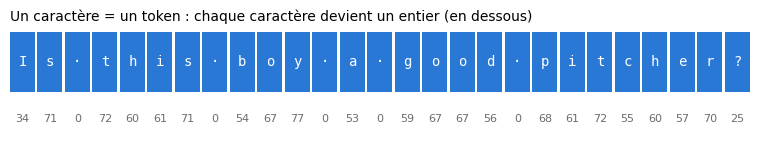

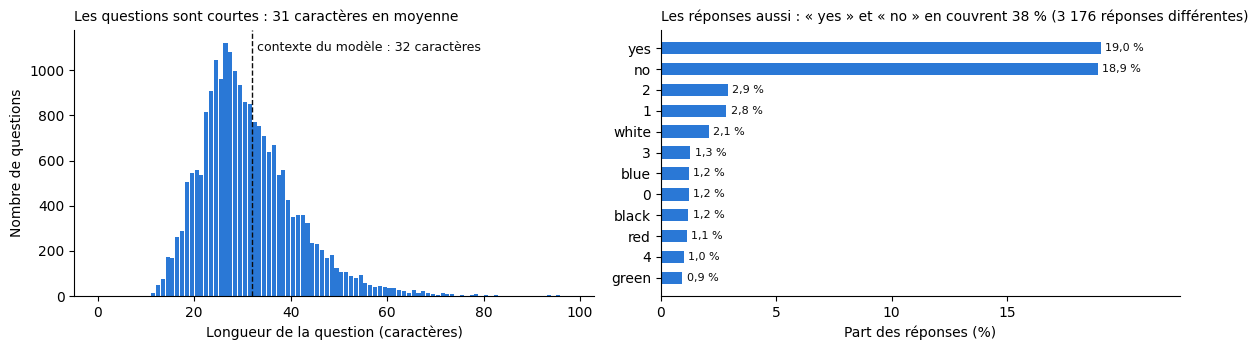

In [7]:
show_tokens(dataset[ind]["question"], encode_txt)
show_text_stats(dataset, cfg)

## 2. Du Transformer (nanoGPT) au ViT

Nous connaissons maintenant le jeu de données : des images et du texte en entrée, du texte en sortie. Il nous faut un modèle qui traite les deux. Nous allons étendre le code du nanoGPT de Karpathy, pour que chaque détail du modèle reste visible. Première étape : en tirer un **Vision Transformer** ([ViT](https://arxiv.org/abs/2010.11929)), un Transformer qui lit une image.

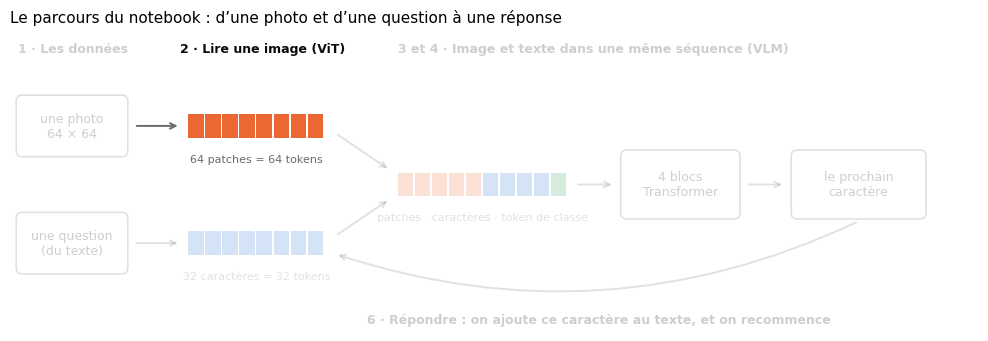

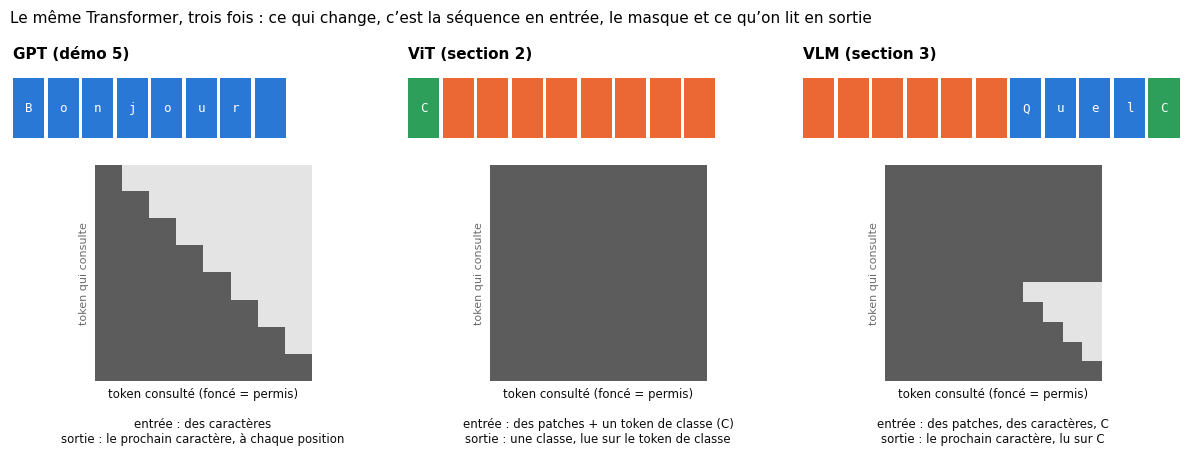

In [8]:
show_flow(stage=2)
show_gpt_vit_vlm()

### 2.1 Passer à un encodeur

Dans le GPT, un masque empêche chaque caractère de consulter les caractères suivants : sinon, il lirait la réponse qu’il doit prédire. C’est un **décodeur**.

Une photo n’a ni passé ni futur. Chaque morceau de l’image peut consulter tous les autres : c’est un **encodeur**. Dans le calcul de l’attention, une seule ligne les sépare.

> **TODO 1.** La cellule suivante contient la ligne du masque du GPT. Que faut-il en faire pour obtenir un encodeur ?

In [ ]:
## Need to adjust the masking.
# We can have fully connected attention (encoder) or partially attended transformers.
# Need to discuss this because we are going to modify this a couple times for our GRP.
# For images we want an encoder
import torch
import torch.nn as nn
from torch.nn import functional as F
# Self-attention
torch.manual_seed(1338)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# One head self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False) ## Here is what I am interested in
query = nn.Linear(C, head_size, bias=False) ## This is what I have
value = nn.Linear(C, head_size, bias=False) ## Here is what I will communicate if you find me useful
k = key(x)   # (B, T, 32)
q = query(x) # (B, T, 32)
wei =  q @ k.transpose(-2, -1) # (B, T, 32) @ (B, 32, T) ---> (B, T, T)

tril = torch.tril(torch.ones(T, T))
# wei = torch.zeros((T,T))
# ==================== TODO 1: your code goes here ====================
# this line is the GPT's mask (a decoder). What do we do with it to get an encoder?
wei = wei.masked_fill(tril == 0, float('-inf'))
# ==================== end of TODO 1 ====================
wei = F.softmax(wei, dim=-1) ## This normalizes the values for a good distribution (sum to 1)

v = value(x)
out = wei @ v
#out = wei @ x

out.shape

torch.Size([4, 8, 16])

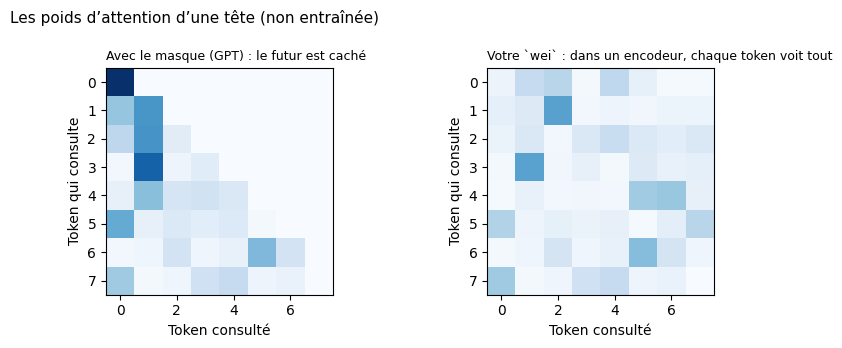

In [10]:
## Look at the attention for one head, with the GPT's mask and with yours
wei_gpt = F.softmax((q @ k.transpose(-2, -1)).masked_fill(tril == 0, float('-inf')), dim=-1)
show_attention(wei_gpt[0], wei[0])

#### Le code du Transformer

Le reste vient de la démo 5, sans le masque : `Head`, `MultiHeadAttention`, `FeedFoward` et `Block`.

In [11]:
import torch
import torch.nn as nn
from torch.nn import functional as F

## This is an encoder head with full attention
class Head(nn.Module):

    def __init__(self, head_size, n_embd, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        ## Why can we remove the buffer below?
        # self.register_buffer('tril', torch.tril(torch.ones(max_max_max_block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        # wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T) ## Remove masking for a encoder
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

class MultiHeadAttention(nn.Module):
    """ Create multiple heads for self-attention in parallel """

    def __init__(self, num_heads, head_size, n_embd, dropout):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size, n_embd=n_embd, dropout=dropout) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication then computation """

    def __init__(self, n_embd, n_head, dropout):
        ## n_embd: embedding dimension, n_head: the number of heads we want
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size, n_embd=n_embd, dropout=dropout)
        self.ffwd = FeedFoward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

### 2.2 Découper l’image en patches

Un Transformer traite des tokens. Le nanoGPT prend chaque lettre comme un token. Les grands modèles de langue découpent plutôt les mots en morceaux, pour bien représenter la langue avec un nombre raisonnable de tokens. Comment découper une image ? On la coupe, littéralement, en $m$ morceaux de même taille : les **patches**.

Ici, une photo de 64 × 64 pixels donne 8 × 8 = 64 patches de 8 × 8 pixels. Chaque patch est aplati en un vecteur de 8 × 8 × 3 = 192 nombres.

In [ ]:
def get_patches_fast(images, cfg):
    """ images: (batch_size, height, width, channels)
        returns: (batch_size, n_patches, patch_size*patch_size*channels)
        
        This code takes an image tensor and splits it into patches using einops rearrange for efficiency.
        Here is a example of the patching process in text form:
           
        """
    from einops import rearrange
    batch_size, height, width, channels = images.shape
    patch_size = cfg.patch_size ## n_patches = 8

    # ==================== TODO 2: your code goes here ====================
    # cut every image into patches of patch_size x patch_size pixels
    ## in:  (b, height, width, c) = (b, 64, 64, 3) = (b, h*p1, w*p2, c)
    ## out: (b, n_patches, patch_size*patch_size*c)
    patches = None
    # ==================== end of TODO 2 ====================
    if channels > 3:
        ## History stacking in the channel dimension for observations only, not goal images.
        patches = rearrange(images, 'b (h p1) (w p2) (c hs) -> b (h w hs) (p1 p2 c)', p1 = patch_size, p2 = patch_size, hs=cfg.policy.obs_stacking) ## Stack the history in the channel dimension
    return patches

Testing get_patches_fast...
Image shape: torch.Size([64, 64, 3])
Patches shape: torch.Size([5, 64, 192])


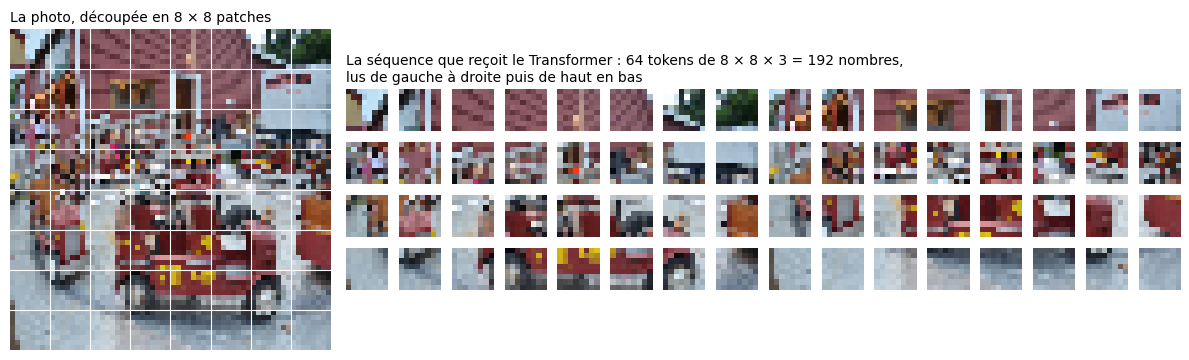

In [13]:
print('Testing get_patches_fast...')
## print out image shape
print("Image shape:", dataset_["image"][0].shape)
out = get_patches_fast(dataset_["image"][:5], cfg)
print("Patches shape:", out.shape)
### Display the photo cut into patches, and the patches in the order the transformer receives them
show_patches(dataset_["image"][0], out[0], cfg)

### 2.3 Les positions

L’attention ne sait pas dans quel ordre arrivent les tokens. Les plongements de position (*positional embeddings*) aident le Transformer à savoir où chaque patch se trouve dans l’image. Selon la tâche, cette information compte plus ou moins.

La démo 5 **apprenait** ses positions. Ici, elles sont **calculées** une fois pour toutes avec des sinus et des cosinus, comme dans [l’article d’origine](https://arxiv.org/abs/1706.03762). Le ViT est décrit dans [cet article](https://arxiv.org/abs/2010.11929).

In [14]:
def calc_positional_embeddings(sequence_length, d):
    out = torch.ones(sequence_length, d)
    for i in range(sequence_length):
        for j in range(d):
            out[i][j] = np.sin(i / (10000 ** (j / d))) if j % 2 == 0 else np.cos(i / (10000 ** ((j - 1) / d)))
    return out

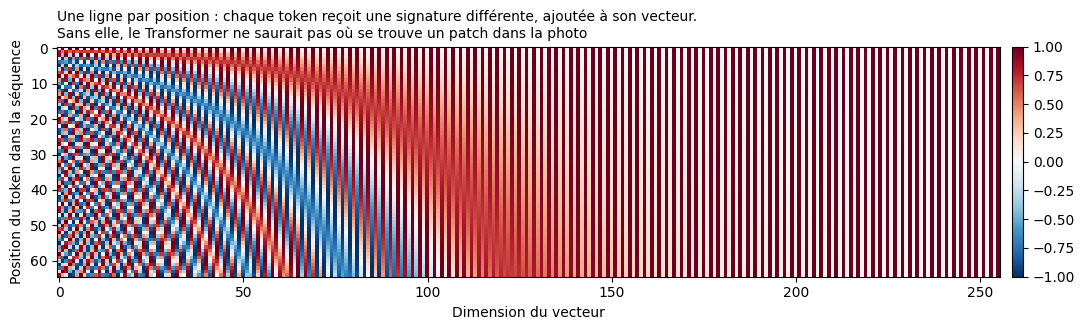

In [15]:
show_positions(calc_positional_embeddings(65, cfg.n_embd))

### 2.4 Le ViT

Il reste à assembler les pièces. Les patches passent par une couche linéaire qui joue le rôle de la table de plongements du GPT. On ajoute un **token de classe** : un vecteur appris, sans contenu propre, qui consulte tous les patches. C’est sur lui qu’on lit la prédiction.

**Que prédire ?** Pour vérifier que le ViT regarde vraiment l’image, nous lui donnons une tâche dont la réponse se voit à l’œil : **quelle moitié de la photo est la plus claire, celle du haut ou celle du bas ?** L’étiquette se calcule à partir des pixels. Les 10 % de lignes de la fin sont mises de côté : le modèle ne s’entraîne jamais dessus.

> **TODO 3.** Dans la classe `VIT`, deux cellules plus bas, écrivez `forward` : des images jusqu’aux logits.

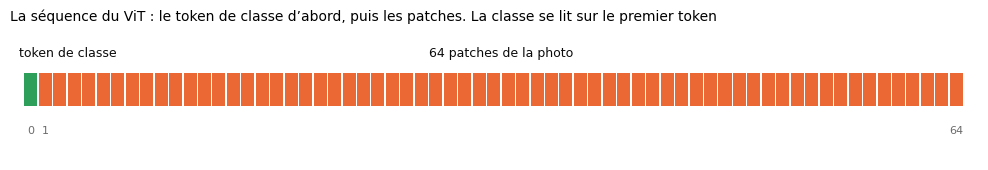

In [16]:
show_sequence("vit", cfg)

In [17]:
## Helper routines to simplify training.

def get_batch(dataset, cfg, split='train'):
    from PIL import Image
    import cv2
    ## Get a batch of data from the hugging face dataset dataset
    n_train = int(0.9 * len(dataset["image"])) ## the last 10% of the rows are held out: the model never trains on them
    ix = np.random.randint(0, n_train, size=(cfg.batch_size)) if split == 'train' else np.random.randint(n_train, len(dataset["image"]), size=(cfg.batch_size))
    X_img = dataset['image'][ix]    
    
    ## Need to get a random section of each row in the txt data that is randomly cropped to max_block_size + 1
    txt = dataset['text2'][ix]  ## plus one for the target token
    ## The target token is the next token after the block
    Y = (X_img[:, 32:].float().mean(dim=(1,2,3)) > X_img[:, :32].float().mean(dim=(1,2,3))).long() ## Target for the ViT: 1 if the bottom half of the photo is brighter than the top half, else 0
    X_text = txt[:, 0:cfg.max_block_size] ## Just ignor this for now
        
    ## Convert images to float32
    X_img = X_img.float() / 255.0
    return X_text, X_img, Y


@torch.no_grad()
def estimate_loss(model, dataset, cfg):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(model._cfg.eval_iters)
        for k in range(model._cfg.eval_iters):
            X_text, X_img, Y = get_batch(dataset, cfg, split)
            logits, loss = model(X_img, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [18]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.optim import Adam
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader

import numpy as np
from tqdm import tqdm, trange
import cv2


class VIT(nn.Module):
  def __init__(self, dataset, cfg, mlp_ratio=4):
    super(VIT, self).__init__()
    self._dataset = dataset
    self._cfg = cfg
    # self.patch_size = (cfg.image_shape[0] / cfg.n_patches, cfg.image_shape[1] / cfg.n_patches)

    #Positional embedding
    self.register_buffer('positional_embeddings', 
                         calc_positional_embeddings((int(cfg.image_shape[0] / cfg.patch_size) ** 2) + 1, 
                                                    cfg.n_embd), persistent=False)

    self.class_tokens = nn.Parameter(torch.rand(1, cfg.n_embd))

    self.input_d = int(cfg.image_shape[2] * (cfg.patch_size * cfg.patch_size))

    self.lin_map = nn.Linear(self.input_d, cfg.n_embd, bias=False)

    # 4) Transformer encoder blocks
    self.blocks = nn.ModuleList([Block(cfg.n_embd, cfg.n_head, dropout=self._cfg.dropout) for _ in range(cfg.n_blocks)])

    # 5) Classification MLP
    self.mlp = nn.Sequential(
        nn.Linear(cfg.n_embd, cfg.action_bins),
    )

  def forward(self, images, targets=None):
    # Dividing images into patches
    n, c, h, w = images.shape
    # ==================== TODO 3: your code goes here ====================
    ## Provide the forward pass of the ViT

    # Divide the images into patches

    # Map the vector corresponding to each patch to the hidden size dimension

    # Add the classification token to the tokens

    # Add the positional embedding

    # Transformer Blocks

    # Get the classification token only, and compute the logits
    logits = None
    # ==================== end of TODO 3 ====================

    if targets is None:
        loss = None
    else:
        # B,T,C = 4,8,2 # batch, time, channels
        B, C = logits.shape
        targets = targets.view(B)
        loss = F.cross_entropy(logits, targets)
    return (logits, loss)

Entraînons-le quelques centaines de pas. La figure se met à jour pendant l’entraînement.

3.225679 M parameters


step 0: train loss 4.8869, val loss 4.8966


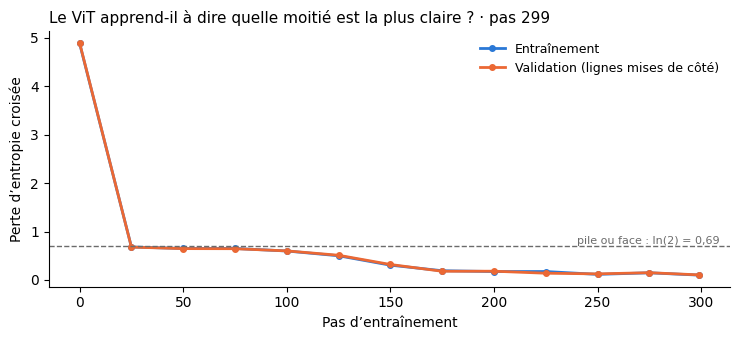

step 25: train loss 0.6817, val loss 0.6791


step 50: train loss 0.6507, val loss 0.6478


step 75: train loss 0.6509, val loss 0.6460


step 100: train loss 0.5986, val loss 0.6008


step 125: train loss 0.5001, val loss 0.5106


step 150: train loss 0.3061, val loss 0.3199


... (3 outputs left out)

step 250: train loss 0.1158, val loss 0.1261


step 275: train loss 0.1480, val loss 0.1502


step 299: train loss 0.1005, val loss 0.1054


results: tensor(0.1054)


In [19]:
cfg.max_iters = 300 ## a value for the class: the config file says 50000
cfg.eval_interval = 25
cfg.eval_iters = 10

def my_main():

    
    model = VIT(dataset_, cfg)
    m = model.to(cfg.device)
    # print the number of parameters in the model
    print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

    # create a PyTorch optimizer
    optimizer = torch.optim.AdamW(model.parameters(), lr=float(cfg.learning_rate))
    live = LiveFigure("Le ViT apprend-il à dire quelle moitié est la plus claire ?", chance=np.log(2), chance_label="pile ou face : ln(2) = 0,69")

    for iter in range(cfg.max_iters):

        # every once in a while evaluate the loss on train and val sets
        if iter % cfg.eval_interval == 0 or iter == cfg.max_iters - 1:
            losses = estimate_loss(model, dataset_, cfg)
            print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
            live.update(iter, losses)

        # sample a batch of data
        xt, xb, yb = get_batch(dataset_, cfg)

        # evaluate the loss
        logits, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    return model, losses['val']

if __name__ == "__main__":
    import os
    vit, results = my_main()
    print("results:", results)

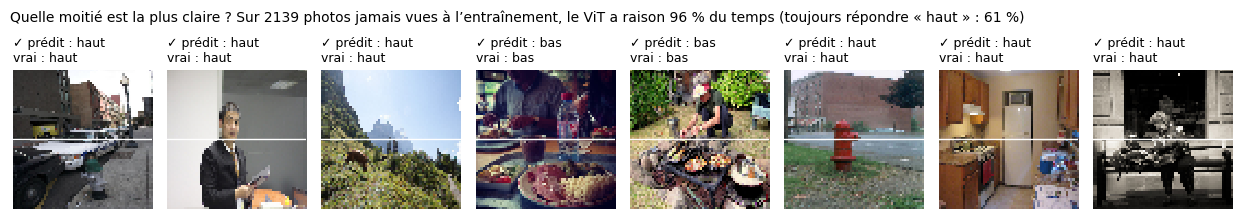

In [20]:
show_vit_predictions(vit, dataset_, cfg)

## 3. Les modèles vision-langage (VLM)

Ces modèles prennent des images **et** du texte en entrée. Nous allons entraîner le nôtre sur le jeu de données VQA :

**(image, question) → VLM → réponse**

Commençons par remettre le texte en entrée.

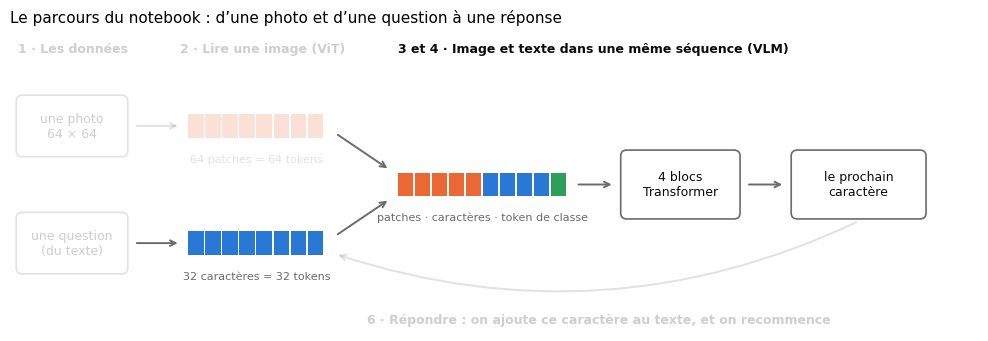

In [21]:
show_flow(stage=3)

### 3.1 Remettre le texte en entrée

Les caractères de la question reçoivent un plongement, comme dans le GPT, et rejoignent les patches **dans la même séquence** : 64 patches, 32 caractères, puis le token de classe. Cela fait 97 tokens.

Le token de classe passe à la fin. Le modèle ne prédit plus une classe d’image : il prédit **le prochain caractère**, et c’est sur ce dernier token qu’on le lit.

> **TODO 4, 5 et 6.** Tous les trois dans la classe `VLM` ci-dessous. **TODO 4** (`__init__`) : la table des positions et la table de plongements du texte. **TODO 5** (`forward`) : construire la séquence. **TODO 6** (`generate`) : la boucle qui écrit la réponse, dont nous aurons besoin à la section 6.

torch.Size([21388, 65]) '     Is this boy a good pitcher?yes                              '


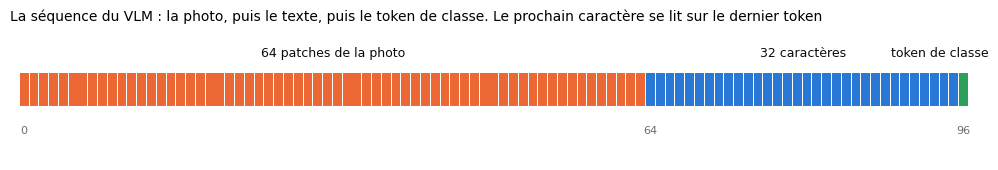

In [22]:
## The data of section 1 already holds the text: one padded line of tokens per photo
print(dataset_["text2"].shape, repr(decode_txt(dataset_["text2"][ind].tolist())))
show_sequence("vlm", cfg)

In [23]:
class VLM(nn.Module):
  def __init__(self, cfg, mlp_ratio=4):
    super(VLM, self).__init__()
    # self._dataset = dataset
    self._cfg = cfg
    # self.patch_size = (self._cfg.image_shape[0] / self._cfg.n_patches, self._cfg.image_shape[1] / self._cfg.n_patches)
    # ==================== TODO 4: your code goes here ====================
    ## Two things change from the ViT

    # Positional embedding: how many tokens does the sequence hold now? (self.positional_embeddings)

    # The embedding table for the text tokens, as in the GPT (self.token_embedding_table)
    # ==================== end of TODO 4 ====================
    self.class_tokens = nn.Parameter(torch.rand(1, cfg.n_embd))

    self.input_d = int(self._cfg.image_shape[2] * cfg.patch_size * cfg.patch_size)

    self.lin_map = nn.Linear(self.input_d, self._cfg.n_embd, bias=False) 

    # 4) Transformer encoder blocks
    self.blocks = nn.ModuleList([Block(self._cfg.n_embd, self._cfg.n_head, dropout=self._cfg.dropout, cfg=cfg) for _ in range(self._cfg.n_blocks)])

    # 5) Classification MLPk
    self.mlp = nn.Sequential(
        nn.Linear(self._cfg.n_embd, self._cfg.action_bins),  # Output size is action_bins 
    )
    self.mlp_m1 = nn.Sequential(
        nn.Linear(self._cfg.n_embd, 12),  # Output size is action_bins
    )

  def _init_weights(self, module):
      if isinstance(module, nn.Linear):
          torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
          if module.bias is not None:
              torch.nn.init.zeros_(module.bias)
      elif isinstance(module, nn.Embedding):
          torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

  def forward(self, X_text, X_images, targets):
    # Dividing images into patches
    n, c, h, w = X_images.shape

    obs_patches = get_patches_fast(X_images, self._cfg) 
    # ==================== TODO 5: your code goes here ====================
    ## Build one sequence from the photo and the text

    # Embed the text tokens (goals_e)

    # Map the vector corresponding to each patch to the hidden size dimension (out_obs)

    # Concatenate: the patches, then the text, then the classification token
    out = None
    # ==================== end of TODO 5 ====================
    
    # Adding positional embedding
    out = out + self.positional_embeddings.repeat(n, 1, 1)
    
    # Transformer Blocks
    for block in self.blocks:
        out = block(out)

    # Getting the classification token only as the last 1 token(s)
    out = out[:, -1]
    logits = self.mlp(out)
        
    if targets is None:
        loss = None
    else:
        B, C = logits.shape
        targets = targets.view(B)
        loss = F.cross_entropy(logits, targets)
    return (logits, loss)
  
  def generate(self, idx, image, max_new_tokens, cfg):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # ==================== TODO 6: your code goes here ====================
            ## The GPT's generation loop, with the image as a second input

            # crop idx to the last block_size tokens

            # get the predictions

            # apply softmax to get probabilities

            # sample from the distribution

            # append sampled index to the running sequence
            pass
            # ==================== end of TODO 6 ====================
        return idx
  

### 3.2 Un masque causal pour le texte seulement

Le VLM lit une photo **et** écrit du texte. Il lui faut donc les deux comportements de la section 2.1 à la fois :

- les **patches** consultent toute la séquence, comme dans un encodeur ;
- les **caractères** consultent la photo et les caractères précédents, mais pas les suivants, comme dans le GPT.

C’est un **masque par blocs**. Dans le code, `wei[:, 64:]` désigne les lignes à partir du token 64, c’est-à-dire tout ce qui vient après les 64 patches.

> **TODO 7.** Dans `Head.forward`, deux cellules plus bas, écrivez le masque par blocs.

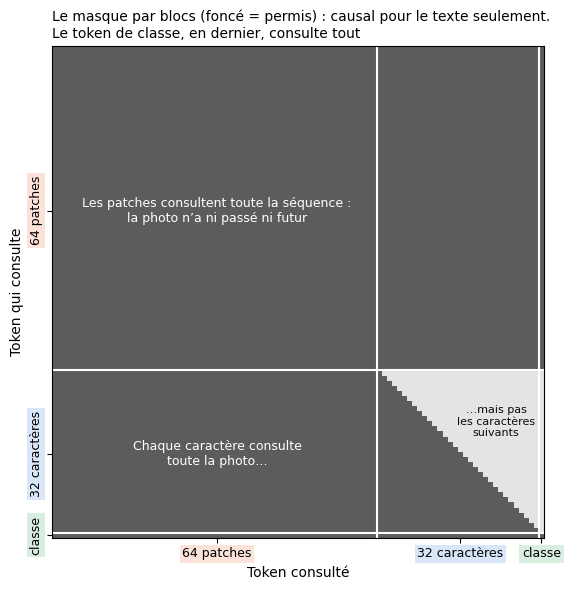

In [24]:
show_block_mask(cfg)

In [25]:
## Need to update some to the transformer code for VLM to include the 
## This is an encoder head (full attention)
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size, n_embd, dropout, cfg):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        ## Need to create the context length and masking size
        context_length = cfg.max_block_size + (int(cfg.image_shape[0] / cfg.patch_size) ** 2) + 1
        self.register_buffer('tril', torch.tril(torch.ones(context_length, context_length)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        ### Block masked attention
        # ==================== TODO 7: your code goes here ====================
        ## Provide the block masking
        pass
        # ==================== end of TODO 7 ====================
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size, n_embd, dropout, cfg):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size, n_embd=n_embd, dropout=dropout, cfg=cfg) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        with torch.profiler.record_function("Self-Attention"):
            out = torch.cat([h(x, mask) for h in self.heads], dim=-1)
            out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), ## This is where the information may be stored.
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x,)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head, dropout, cfg):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size, n_embd=n_embd, dropout=dropout, cfg=cfg)
        self.ffwd = FeedFoward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x, mask=None):
        x = x + self.sa(self.ln1(x), mask)
        x = x + self.ffwd(self.ln2(x))
        return x

### 3.3 Compléter le texte, et former les batchs à partir de sous-chaînes

Le GPT de la démo 5 lisait un seul long texte et y découpait des fenêtres au hasard. Ici, nous avons 21 000 petits textes de longueurs différentes. Deux étapes :

- **Compléter** (*padding*). Chaque ligne est ramenée à 65 caractères avec des espaces. La question est alignée à droite sur 32 caractères, la taille du contexte : la réponse commence donc toujours juste après.
- **Découper des sous-chaînes.** Un exemple d’entraînement est une fenêtre de 32 caractères tirée au hasard dans la ligne, et le caractère qui la suit : la **cible**. La même ligne donne ainsi plusieurs exemples, un pour chaque caractère de la réponse.

> **TODO 8.** Dans `get_batch`, deux cellules plus bas, découpez les fenêtres et prenez la cible.

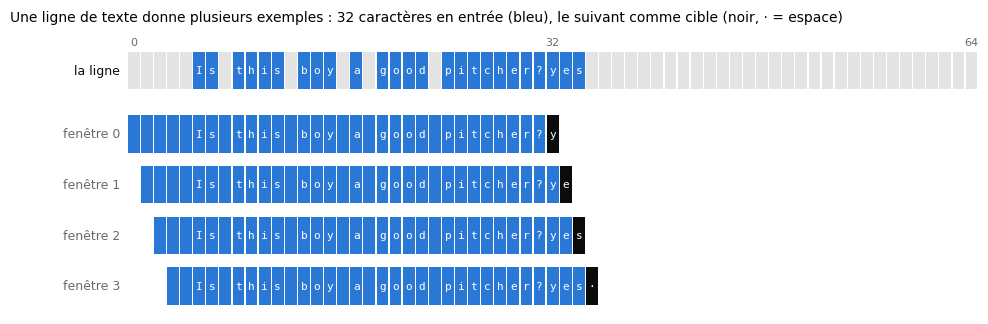

In [26]:
show_windows(dataset_, cfg, ind, decode_txt)

In [27]:
def get_batch(dataset, cfg, split='train'):
    from PIL import Image
    import cv2
    ## Get a batch of data from the hugging face dataset dataset
    n_train = int(0.9 * len(dataset["image"])) ## the last 10% of the rows are held out: the model never trains on them
    ix = np.random.randint(0, n_train, size=(cfg.batch_size)) if split == 'train' else np.random.randint(n_train, len(dataset["image"]), size=(cfg.batch_size))
    X_img = dataset['image'][ix]    
    
    # ==================== TODO 8: your code goes here ====================
    ## Need to get a random section of each row in the txt data that is randomly cropped to max_block_size + 1

    # For each row, draw where the crop starts (dataset['text_lengths'][ix] gives the usable length of each row)

    # Grab the crops of max_block_size + 1 tokens from dataset['text2'][ix]

    # The first max_block_size tokens are the input, the target token is the next one
    X_text, Y = None, None
    # ==================== end of TODO 8 ====================
        
    ## Convert images to float32
    X_img = X_img.float() / 255.0
    return X_text, X_img, Y


@torch.no_grad()
def estimate_loss(model, dataset, cfg, encode_txt):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(model._cfg.eval_iters)
        for k in range(model._cfg.eval_iters):
            X_text, X_img, Y = get_batch(dataset, cfg, split)
            logits, loss = model(X_text, X_img, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [28]:
## One batch, to look at what the model receives
xq, xi, yb = get_batch(dataset_, cfg)
print("text:", tuple(xq.shape), "| images:", tuple(xi.shape), "| targets:", tuple(yb.shape))
for i in range(4):
    print(repr(decode_txt(xq[i].tolist())), "->", repr(decode_txt([yb[i].item()])))

text: (64, 32) | images: (64, 64, 64, 3) | targets: (64,)


'ny stripes are visible on the an' -> 'i'
'y suitcases are in the hallway?0' -> ' '
'    What color is the tile?white' -> ' '
' What are the people doing?skiin' -> 'g'


## 4. Entraîner le modèle

Les réglages viennent du fichier de configuration : 4 blocs, 16 têtes par bloc, des vecteurs de 256 nombres, un taux d’apprentissage de 5e-5. Cela donne environ 3,2 millions de paramètres.

**Quelle perte attendre au départ ?** Un modèle qui ne sait rien donne la même probabilité aux 79 caractères du vocabulaire : sa perte vaut ln(79) ≈ 4,37. Vérifions-le avant d’entraîner.

In [29]:
torch.manual_seed(cfg.r_seed)
model = VLM(cfg).to(cfg.device)
logits, loss = model(xq, xi, yb)
print("logits:", tuple(logits.shape), "| loss before training:", round(loss.item(), 3), "| uniform guess: ln(79) =", round(float(np.log(cfg.vocab_size)), 3))

logits: (64, 79) | loss before training: 4.627 | uniform guess: ln(79) = 4.369


En classe, nous entraînons le modèle 1 000 pas : assez pour voir la perte descendre, pas assez pour de bonnes réponses. L’entraînement complet (`FULL_RUN = True`, 30 000 pas) est beaucoup plus long : environ 1 h 40 sur le GPU d’un Mac récent.

Pendant l’entraînement, la figure montre les deux courbes de perte et, à droite, une photo mise de côté avec la réponse du modèle à cet instant.

In [30]:
FULL_RUN = False ## True: the long training, 30000 steps
cfg.max_iters = 30000 if FULL_RUN else 1000 ## the config file says 50000
cfg.eval_interval = 1000 if FULL_RUN else 100
cfg.eval_iters = 10

## A held-out row, shown during training with the model's current answer
n_train = int(0.9 * len(dataset_["image"]))
example = (dataset_["image"][n_train + 45], dataset[n_train + 45]["question"], dataset[n_train + 45]["multiple_choice_answer"])

3.248987 M parameters


step 0: train loss 4.5311, val loss 4.5612, memory 0.00 MB
Q: s there a shower in this room?no


A: s there a shower in this room?no1+X+N+/4"s`3ggVo4(x.96)KiUx'L.O'


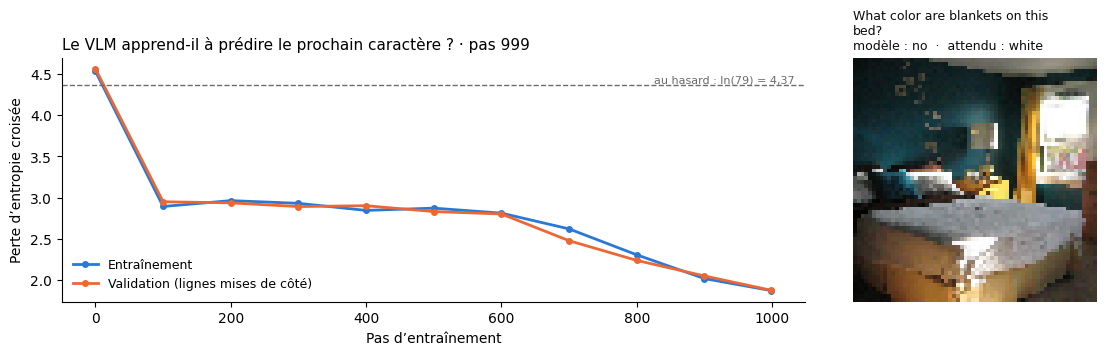

step 100: train loss 2.8938, val loss 2.9510, memory 0.00 MB
Q: rse do this because it wants to?


A: rse do this because it wants to?aKe v oor e tfota o  g  o1 s1 kr


step 200: train loss 2.9649, val loss 2.9379, memory 0.00 MB
Q:          What is on the floor?ti


A:          What is on the floor?ti  n trsu lo sp   ?d r2sea?ub?kbe


step 300: train loss 2.9319, val loss 2.8927, memory 0.00 MB
Q: long neck tie or a bow tie?bow t


A: long neck tie or a bow tie?bow tfsrhoa0uuri ohossacir? onkakle?e


... (11 outputs left out)

A: ng the proper gear for the sportide?ys ife oawt?1 w  asu 2eo cus


step 999: train loss 1.8745, val loss 1.8783, memory 0.00 MB
Q:   How many fingers can you see?4


A:   How many fingers can you see?4 o5 illithy wng hiP1r Xceluuraak


Model saved to ./microVLM.pth


In [31]:
import os
from box import Box
def my_main():
    torch.manual_seed(cfg.r_seed)
    
    model = VLM(cfg)
    model.to(device)
    print(sum(p.numel() for p in model.parameters())/1e6, 'M parameters')
    ## Print the amount of memory used by the model
    # print("Memory used by the model:", torch.cuda.memory_allocated(device) / 1e6, "MB")
    ## Print the amount of memory used by the dataset cBuffer
    # cBuffer.print_mem_footprint()


    # create a PyTorch optimizer
    optimizer = torch.optim.AdamW(model.parameters(), lr=float(cfg.learning_rate))
    import torch.optim.lr_scheduler as lr_scheduler
    scheduler = lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=cfg.max_iters)
    live = LiveFigure("Le VLM apprend-il à prédire le prochain caractère ?", chance=np.log(cfg.vocab_size), chance_label="au hasard : ln(79) = 4,37", example=example)

    for iter in range(cfg.max_iters):

        if iter % cfg.eval_interval == 0 or iter == cfg.max_iters - 1:
            losses = estimate_loss(model, dataset_, cfg, encode_txt)
            print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}, memory {torch.cuda.memory_allocated(device) / 1e6:.2f} MB")
            xq, xi, yb = get_batch(dataset_, cfg)
            print("Q: " + decode_txt(xq[0].tolist())) ## Print the question
            print("A: " + decode_txt(model.generate(xq[:1], xi[:1], max_new_tokens=cfg.max_block_size, cfg=cfg)[0].tolist())) ## Decode the responses learned so far
            live.update(iter, losses, model)

        if iter == cfg.max_iters - 1:
            path_ = "./microVLM.pth"
            torch.save(model.state_dict(), path_)
            print("Model saved to " + path_)

        # if iter % cfg.data_shuffel_interval == 0 and iter > 0:
        #     ## Update the dataset
        #     shared_queue.put('shuffle')

        xq, xi, yb = get_batch(dataset_, cfg)

        # evaluate the loss
        logits, loss = model(xq, xi, yb)
        loss.backward()

        if (iter + 1) % cfg.gradient_accumulation_steps == 0:
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)

    # shared_queue.put(None)
    # data_thread.join()

    return model, losses['val']

vlm, results = my_main()

## 5. Encoder le texte avec T5

Notre modèle apprend tout à partir de zéro, avec 21 000 questions : les lettres, les mots, l’anglais et les images en même temps. C’est beaucoup demander.

Les vrais VLM ne repartent pas de zéro. Ils **réutilisent des modèles déjà entraînés** : un modèle de texte qui connaît déjà la langue, et souvent un modèle de vision qui connaît déjà les images. L’entraînement sert surtout à apprendre à les faire travailler ensemble.

Le code du dépôt prévoit ce cas. Avec `encode_with_t5: true` dans la configuration, `VLM.forward` ne passe plus par `token_embedding_table` : il reçoit directement, à la place des caractères, les vecteurs produits par [T5](https://arxiv.org/abs/1910.10683), un modèle de texte préentraîné. Nous ne l’exécutons pas ici.

## 6. Générer des réponses

Pour répondre, le modèle fait ce que faisait le GPT : il prédit un caractère, l’ajoute au texte, et recommence. `VLM.generate` contient cette boucle, avec la photo comme deuxième entrée.

Les réponses sont plus intéressantes avec un modèle entraîné longtemps. La cellule suivante charge celui de l’entraînement complet (30 000 pas) s’il est disponible. Sinon, elle garde le modèle de la section 4.

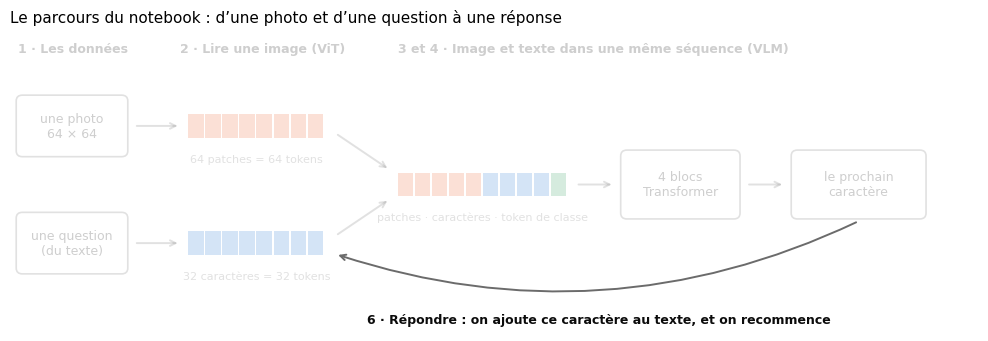

In [32]:
show_flow(stage=4)

In [33]:
CHECKPOINT_PATH = "microVLM_30k.pth" ## microVLM.pth from a full run, renamed
CHECKPOINT_URL = "" ## where the file is hosted, once it is

if not os.path.exists(CHECKPOINT_PATH) and CHECKPOINT_URL:
    urllib.request.urlretrieve(CHECKPOINT_URL, CHECKPOINT_PATH)
if os.path.exists(CHECKPOINT_PATH):
    vlm = VLM(cfg).to(cfg.device)
    vlm.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=cfg.device))
    print("Loaded the model of the full run:", CHECKPOINT_PATH)
else:
    print(f"No file {CHECKPOINT_PATH}: the answers below come from the model trained in section 4 ({cfg.max_iters} steps).")
vlm.eval();

No file microVLM_30k.pth: the answers below come from the model trained in section 4 (1000 steps).


Poser une question demande deux précautions :

- **donner la question comme à l’entraînement,** alignée à droite dans le contexte de 32 caractères ;
- **s’arrêter au premier espace.** Le modèle a appris à écrire un espace à la fin de sa réponse, et rien de ce qui vient après.

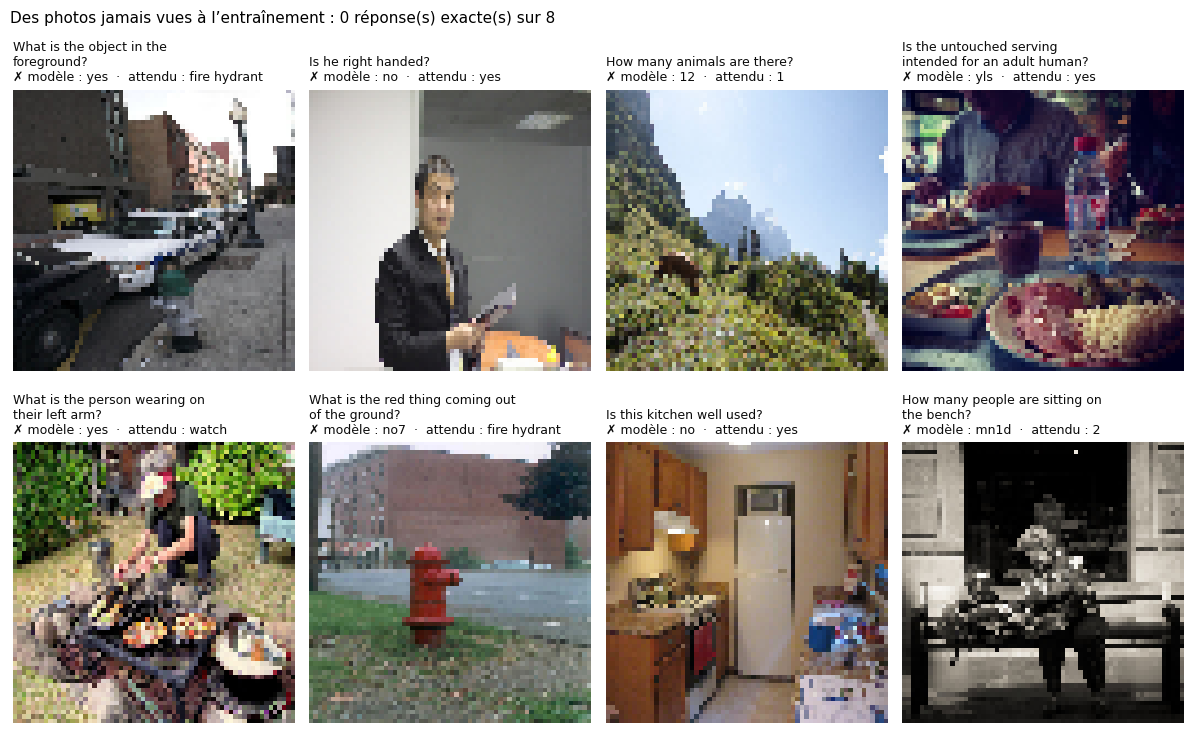

In [34]:
def ask(model, images, questions, max_new_tokens=12):
    ## The questions, right-aligned in the context of max_block_size characters, as tokens
    context = torch.tensor([encode_txt(q.rjust(cfg.max_block_size)[-cfg.max_block_size:]) for q in questions], device=cfg.device)
    with torch.no_grad():
        out = model.generate(context, images.float() / 255.0, max_new_tokens=max_new_tokens, cfg=cfg)
    ## Keep what was written after the question, up to the first space
    return [decode_txt(row[cfg.max_block_size:].tolist()).split(" ")[0] for row in out]

questions, truths = list(dataset["question"]), list(dataset["multiple_choice_answer"])
rows = np.arange(n_train, n_train + 8) ## held-out rows
torch.manual_seed(0)
answers = ask(vlm, dataset_["image"][rows], [questions[i] for i in rows])
show_answers(dataset_["image"][rows], [questions[i] for i in rows], answers, [truths[i] for i in rows])

Huit photos ne disent pas grand-chose. Mesurons sur 500 questions mises de côté, et comparons à deux façons de répondre **sans regarder la photo** : toujours dire « yes », ou donner la réponse la plus fréquente pour les deux premiers mots de la question (« How many » → « 2 »). Un VLM utile doit faire mieux que les deux.

In [35]:
from collections import Counter

rows = np.arange(n_train, n_train + 500)
torch.manual_seed(0)
answers = ask(vlm, dataset_["image"][rows], [questions[i] for i in rows])

## Two ways to answer without looking at the photo, built from the training rows only
start = lambda q: " ".join(q.split()[:2])
by_start = {}
for i in range(n_train):
    by_start.setdefault(start(questions[i]), Counter())[truths[i]] += 1
blind = [by_start[start(questions[i])].most_common(1)[0][0] if start(questions[i]) in by_start else "yes" for i in rows]

print(f"The model:                       {np.mean([a == truths[i] for a, i in zip(answers, rows)]):.1%} exact answers")
print(f"Always 'yes':                    {np.mean([truths[i] == 'yes' for i in rows]):.1%}")
print(f"Most frequent answer, 2 words:   {np.mean([b == truths[i] for b, i in zip(blind, rows)]):.1%}")

The model:                       14.8% exact answers
Always 'yes':                    21.0%
Most frequent answer, 2 words:   27.4%


Enfin, regardons où le token de classe porte son attention au moment d’écrire le premier caractère de la réponse. Sur un modèle aussi petit, la carte reste souvent diffuse : c’est un indice, pas une preuve que le modèle regarde au bon endroit.

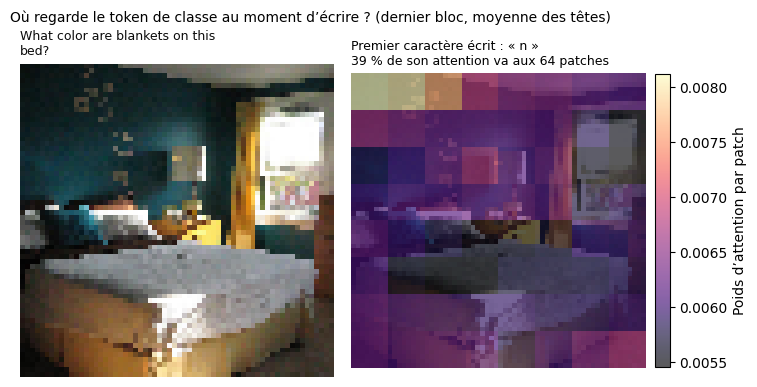

In [36]:
show_class_attention(vlm, dataset_["image"][n_train + 45], questions[n_train + 45], cfg)

## À retenir

- Un **ViT** est le Transformer de la démo 5 avec trois changements : pas de masque, des **patches** à la place des caractères, et un **token de classe** sur lequel on lit la prédiction.
- Un **VLM** met l’image et le texte **dans une même séquence**. Les blocs Transformer ne changent pas : seuls changent ce qu’on met dans la séquence et le masque.
- Le **masque par blocs** laisse les patches tout consulter et garde le texte causal.
- Générer une réponse, c’est **prédire le prochain caractère, encore et encore**, comme le GPT, avec la photo en plus.
- Un modèle qui répond « yes » partout a souvent raison. Il faut toujours **comparer à une réponse donnée sans regarder la photo** avant de conclure que le modèle voit.
- Les vrais VLM **réutilisent des modèles préentraînés** pour le texte et pour l’image, et sont entraînés sur beaucoup plus de données.